In [1]:
# %% [Cell 1] Setup & Configuration

import os
import random
import warnings
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
rng = np.random.default_rng(SEED)

# Core Configuration
CONFIG = {
    "n_customers": 50_000,
    "n_transactions": 500_000,
    "fraud_rate": 0.005,
    "simulation_start": datetime(2025, 1, 1),
    "simulation_end": datetime(2026, 1, 1),
    "train_end": datetime(2025, 10, 1),
    "test_start": datetime(2025, 10, 1),
}

# Yemeni E-Wallets
WALLETS = {
    'Jaib':       {'code': 1, 'market_share': 0.20, 'fee_rate': 0.012},
    'Jawali':     {'code': 0, 'market_share': 0.18, 'fee_rate': 0.010},
    'Alkuraimi':  {'code': 3, 'market_share': 0.15, 'fee_rate': 0.008},
    'Cash':       {'code': 2, 'market_share': 0.12, 'fee_rate': 0.015},
    'Flosak':     {'code': 4, 'market_share': 0.10, 'fee_rate': 0.010},
    'SabaCash':   {'code': 5, 'market_share': 0.08, 'fee_rate': 0.011},
    'BiCash':     {'code': 6, 'market_share': 0.06, 'fee_rate': 0.012},
    'YemenCash':  {'code': 7, 'market_share': 0.05, 'fee_rate': 0.010},
    'Mahfathati': {'code': 8, 'market_share': 0.04, 'fee_rate': 0.008},
    'M-Floos':    {'code': 9, 'market_share': 0.02, 'fee_rate': 0.009},
}

# Governorates
GOVERNORATES = {
    "Sanaa":      {"code": 0,  "risk": "high",   "pop_weight": 0.15, "econ_mult": 1.20},
    "Aden":       {"code": 1,  "risk": "high",   "pop_weight": 0.10, "econ_mult": 1.30},
    "Taiz":       {"code": 2,  "risk": "high",   "pop_weight": 0.12, "econ_mult": 1.00},
    "Hodeidah":   {"code": 3,  "risk": "high",   "pop_weight": 0.10, "econ_mult": 0.90},
    "Hadramout":  {"code": 4,  "risk": "high",   "pop_weight": 0.07, "econ_mult": 1.10},
    "Ibb":        {"code": 5,  "risk": "medium", "pop_weight": 0.08, "econ_mult": 0.95},
    "Dhamar":     {"code": 6,  "risk": "medium", "pop_weight": 0.05, "econ_mult": 0.90},
    "Amran":      {"code": 7,  "risk": "medium", "pop_weight": 0.04, "econ_mult": 0.85},
    "Saada":      {"code": 8,  "risk": "medium", "pop_weight": 0.03, "econ_mult": 0.80},
    "Marib":      {"code": 9,  "risk": "medium", "pop_weight": 0.04, "econ_mult": 1.05},
    "Hajjah":     {"code": 10, "risk": "medium", "pop_weight": 0.04, "econ_mult": 0.85},
    "AlBayda":    {"code": 11, "risk": "medium", "pop_weight": 0.03, "econ_mult": 0.80},
    "AlJawf":     {"code": 12, "risk": "medium", "pop_weight": 0.02, "econ_mult": 0.85},
    "Lahj":       {"code": 13, "risk": "medium", "pop_weight": 0.03, "econ_mult": 0.85},
    "Abyan":      {"code": 14, "risk": "medium", "pop_weight": 0.02, "econ_mult": 0.85},
    "AlMahrah":   {"code": 15, "risk": "low",    "pop_weight": 0.01, "econ_mult": 1.10},
    "AlMahwit":   {"code": 16, "risk": "low",    "pop_weight": 0.02, "econ_mult": 0.80},
    "Raymah":     {"code": 17, "risk": "low",    "pop_weight": 0.01, "econ_mult": 0.80},
    "Socotra":    {"code": 18, "risk": "low",    "pop_weight": 0.005,"econ_mult": 1.20},
    "Shabwah":    {"code": 19, "risk": "low",    "pop_weight": 0.01, "econ_mult": 0.90},
    "AdhDhale":   {"code": 20, "risk": "low",    "pop_weight": 0.015,"econ_mult": 0.95},
    "AlHudaydah": {"code": 21, "risk": "low",    "pop_weight": 0.005,"econ_mult": 0.85},
}

# KYC Levels
KYC_LEVELS = {
    "basic":        {"code": 0, "weight": 0.40, "daily_limit": 200_000,   "base_amount": 15_000},
    "intermediate": {"code": 1, "weight": 0.40, "daily_limit": 1_000_000, "base_amount": 50_000},
    "verified":     {"code": 2, "weight": 0.20, "daily_limit": 5_000_000, "base_amount": 200_000},
}

print("Setup completed. Configuration loaded.")

Setup completed. Configuration loaded.


In [2]:
# %% [Cell 2] Customer Generator

class CustomerGeneratorV2:
    def __init__(self, config, wallets, governorates, kyc_levels, seed=42):
        self.config = config
        self.wallets = wallets
        self.governorates = governorates
        self.kyc_levels = kyc_levels
        self.rng = np.random.default_rng(seed)

    def generate(self):
        n = self.config["n_customers"]

        # Wallet
        w_names = list(self.wallets.keys())
        w_weights = np.array([self.wallets[w]["market_share"] for w in w_names])
        w_weights = w_weights / w_weights.sum()
        wallet_choices = self.rng.choice(w_names, size=n, p=w_weights)

        # Governorate
        g_names = list(self.governorates.keys())
        g_weights = np.array([self.governorates[g]["pop_weight"] for g in g_names])
        g_weights = g_weights / g_weights.sum()
        gov_choices = self.rng.choice(g_names, size=n, p=g_weights)

        # KYC
        k_names = list(self.kyc_levels.keys())
        k_weights = np.array([self.kyc_levels[k]["weight"] for k in k_names])
        k_weights = k_weights / k_weights.sum()
        kyc_choices = self.rng.choice(k_names, size=n, p=k_weights)

        # Account age
        age_days = self.rng.lognormal(mean=4.5, sigma=1.5, size=n).astype(int)
        age_days = np.clip(age_days, 1, 1825)

        # Creation date
        start_date = self.config["simulation_start"]
        creation_dates = [start_date - timedelta(days=int(age)) for age in age_days]

        # Profile
        profile_choices = self.rng.choice(
            ["normal", "active", "dormant"], size=n, p=[0.60, 0.25, 0.15]
        )

        # Bursts tendency
        bursts = []
        for p in profile_choices:
            if p == "active":
                bursts.append(int(self.rng.integers(5, 16)))
            elif p == "normal":
                bursts.append(int(self.rng.integers(2, 6)))
            else:
                bursts.append(int(self.rng.integers(1, 3)))

        # Phone
        prefixes = ["73", "77", "71", "70", "78"]
        phones = [f"+967{self.rng.choice(prefixes)}{self.rng.integers(1000000, 9999999)}" for _ in range(n)]

        # Avg amount & Limits
        avg_amounts = []
        daily_limits = []
        for k, p, g in zip(kyc_choices, profile_choices, gov_choices):
            base = self.kyc_levels[k]["base_amount"]
            profile_mult = {"normal": 1.0, "active": 1.3, "dormant": 0.7}[p]
            gov_mult = self.governorates[g]["econ_mult"]
            noise = self.rng.uniform(0.75, 1.25)
            avg_amounts.append(int(base * profile_mult * gov_mult * noise))
            daily_limits.append(self.kyc_levels[k]["daily_limit"])

        # Risk score
        gov_risk_val = {"high": 35, "medium": 18, "low": 5}
        kyc_risk_val = {"basic": 25, "intermediate": 12, "verified": 0}
        risk_scores = []
        for g, k, age, p in zip(gov_choices, kyc_choices, age_days, profile_choices):
            s = gov_risk_val[self.governorates[g]["risk"]] + kyc_risk_val[k]
            s -= min(25, age / 365 * 5)
            if p == "dormant":
                s += 5
            risk_scores.append(int(np.clip(s, 0, 100)))

        # Build DataFrame
        customers = pd.DataFrame({
            "customer_id": [f"C{str(i).zfill(7)}" for i in range(n)],
            "wallet": wallet_choices,
            "wallet_code": [self.wallets[w]["code"] for w in wallet_choices],
            "governorate": gov_choices,
            "governorate_code": [self.governorates[g]["code"] for g in gov_choices],
            "governorate_risk": [self.governorates[g]["risk"] for g in gov_choices],
            "kyc_level": kyc_choices,
            "kyc_code": [self.kyc_levels[k]["code"] for k in kyc_choices],
            "account_age_days": age_days,
            "account_creation_date": creation_dates,
            "profile": profile_choices,
            "bursts_tendency": bursts,
            "phone": phones,
            "risk_score": risk_scores,
            "daily_limit_yer": daily_limits,
            "avg_txn_amount_yer": avg_amounts,
        })
        return customers

gen = CustomerGeneratorV2(CONFIG, WALLETS, GOVERNORATES, KYC_LEVELS, seed=SEED)
customers = gen.generate()

print(f"Generated {len(customers):,} customers.")
customers.to_csv('customers_v2.csv', index=False)

Generated 50,000 customers.


In [3]:
# %% [Cell 3] Normal Transactions (Balanced Bursts)

import time

print("Generating normal transactions...")
t_start = time.time()

TXN_TYPES = {
    "transfer":         {"weight": 0.40, "hour_bias": "day_evening"},
    "merchant_payment": {"weight": 0.20, "hour_bias": "day"},
    "bill_payment":     {"weight": 0.15, "hour_bias": "day"},
    "cash_withdrawal":  {"weight": 0.10, "hour_bias": "day"},
    "salary":           {"weight": 0.08, "hour_bias": "morning"},
    "topup":            {"weight": 0.07, "hour_bias": "any"},
}

def build_hour_weights(bias):
    w = np.ones(24) * 0.3
    if bias == "morning":
        for h in range(7, 12): w[h] = 3.0
    elif bias == "day":
        for h in range(8, 19): w[h] = 2.5
    elif bias == "day_evening":
        for h in range(8, 22): w[h] = 2.5
        for h in range(18, 23): w[h] = 3.0
    elif bias == "any":
        for h in range(6, 23): w[h] = 1.5
    return w / w.sum()

HOUR_WEIGHTS = {b: build_hour_weights(b) for b in ["morning", "day", "day_evening", "any"]}
DAY_WEIGHTS = np.array([0.14, 0.14, 0.14, 0.13, 0.08, 0.16, 0.21])

EVENTS = {
    'ramadan':     {'start': datetime(2025, 3, 1),  'end': datetime(2025, 3, 30), 'amt_mult': 1.4, 'vol_mult': 1.6},
    'eid_fitr':    {'start': datetime(2025, 3, 31), 'end': datetime(2025, 4, 3),  'amt_mult': 1.8, 'vol_mult': 2.0},
    'eid_adha':    {'start': datetime(2025, 6, 6),  'end': datetime(2025, 6, 9),  'amt_mult': 2.2, 'vol_mult': 1.8},
    'school_start':{'start': datetime(2025, 9, 1),  'end': datetime(2025, 9, 15), 'amt_mult': 1.3, 'vol_mult': 1.3},
    'new_year':    {'start': datetime(2025, 12, 25),'end': datetime(2026, 1, 5),  'amt_mult': 1.2, 'vol_mult': 1.3},
}

def get_event_mult(date):
    amt, vol = 1.0, 1.0
    for ev in EVENTS.values():
        if ev['start'] <= date <= ev['end']:
            amt = max(amt, ev['amt_mult'])
            vol = max(vol, ev['vol_mult'])
    return amt, vol

def build_txn_fields(cust, day, hour_weights, amt_mult, rng):
    type_names = list(TXN_TYPES.keys())
    type_weights = np.array([TXN_TYPES[t]['weight'] for t in type_names])
    if cust['profile'] == 'active':
        type_weights[type_names.index('transfer')] *= 1.3
        type_weights[type_names.index('merchant_payment')] *= 1.2
    elif cust['profile'] == 'dormant':
        type_weights[type_names.index('cash_withdrawal')] *= 1.5
    type_weights /= type_weights.sum()

    txn_type = rng.choice(type_names, p=type_weights)
    hour = int(rng.choice(24, p=hour_weights))
    minute = int(rng.integers(0, 60))
    second = int(rng.integers(0, 60))

    avg_amt = cust['avg_txn_amount_yer']
    amount = int(rng.lognormal(mean=np.log(avg_amt), sigma=0.4) * amt_mult)
    amount = max(int(avg_amt * 0.2), min(amount, int(avg_amt * 2.5)))

    return txn_type, hour, minute, second, amount

N_NORMAL = 497_500
customers_list = customers.to_dict('records')
customer_by_id = {c['customer_id']: c for c in customers_list}
all_customer_ids = np.array([c['customer_id'] for c in customers_list])

PROFILE_WEIGHT = {"active": 3.0, "normal": 1.0, "dormant": 0.3}
cust_weights = np.array([PROFILE_WEIGHT[c['profile']] for c in customers_list])
cust_weights = cust_weights / cust_weights.sum()
txns_per_cust = rng.multinomial(N_NORMAL, cust_weights)

sim_start = CONFIG["simulation_start"]
sim_end = CONFIG["simulation_end"]
total_days = (sim_end - sim_start).days
all_dates = [sim_start + timedelta(days=i) for i in range(total_days)]

day_weights = np.array([DAY_WEIGHTS[d.weekday()] for d in all_dates], dtype=float)
for i, d in enumerate(all_dates):
    _, vol = get_event_mult(d)
    day_weights[i] *= vol
day_weights = day_weights / day_weights.sum()

transactions = []
txn_counter = 0

for cust_idx, cust in enumerate(customers_list):
    n_txns = txns_per_cust[cust_idx]
    if n_txns == 0:
        continue

    n_known = int(rng.integers(10, 51))
    known_receivers = rng.choice(all_customer_ids, size=n_known, replace=False)
    known_receivers = [r for r in known_receivers if r != cust['customer_id']]

    n_bursts = max(1, int(n_txns * rng.uniform(0.4, 0.6)))
    n_singles = n_txns - n_bursts

    # Singles
    if n_singles > 0:
        single_days = rng.choice(total_days, size=n_singles, p=day_weights)
        for day_idx in single_days:
            day = all_dates[day_idx]
            amt_mult, _ = get_event_mult(day)
            txn_type, hour, minute, second, amount = build_txn_fields(cust, day, HOUR_WEIGHTS["day_evening"], amt_mult, rng)
            if amount > cust['daily_limit_yer']:
                amount = int(cust['daily_limit_yer'] * 0.8)
            ts = day.replace(hour=hour, minute=minute, second=second)

            if txn_type in ('transfer', 'merchant_payment'):
                if known_receivers and rng.random() < 0.70:
                    receiver_id = str(rng.choice(known_receivers))
                else:
                    receiver_id = str(rng.choice(all_customer_ids))
                if receiver_id == cust['customer_id']:
                    receiver_id = str(rng.choice(all_customer_ids))
                receiver = customer_by_id.get(receiver_id)
            else:
                receiver_id, receiver = None, None

            transactions.append({
                'txn_id': f"T{txn_counter:08d}", 'timestamp': ts, 'sender_id': cust['customer_id'],
                'receiver_id': receiver_id, 'txn_type': txn_type, 'amount_yer': amount,
                'sender_wallet': cust['wallet'], 'receiver_wallet': receiver['wallet'] if receiver else None,
                'sender_governorate': cust['governorate'], 'receiver_governorate': receiver['governorate'] if receiver else None,
                'is_fraud': 0
            })
            txn_counter += 1

    # Bursts
    remaining = n_bursts
    burst_sizes = []
    while remaining > 0:
        size = int(rng.integers(3, 9))
        size = min(size, remaining)
        burst_sizes.append(size)
        remaining -= size

    for burst_size in burst_sizes:
        day_idx = rng.choice(total_days, p=day_weights)
        day = all_dates[day_idx]
        window_start = int(rng.integers(8, 20))
        window_hours = list(range(window_start, min(window_start + 4, 24)))
        hour_weights_burst = np.zeros(24)
        for h in window_hours:
            hour_weights_burst[h] = HOUR_WEIGHTS["day"][h]
        if hour_weights_burst.sum() == 0:
            hour_weights_burst = HOUR_WEIGHTS["day"]
        hour_weights_burst = hour_weights_burst / hour_weights_burst.sum()

        amt_mult, _ = get_event_mult(day)
        daily_total = 0

        for _ in range(burst_size):
            txn_type, hour, minute, second, amount = build_txn_fields(cust, day, hour_weights_burst, amt_mult, rng)
            if daily_total + amount > cust['daily_limit_yer']:
                remaining_amt = cust['daily_limit_yer'] - daily_total
                if remaining_amt < cust['avg_txn_amount_yer'] * 0.2:
                    continue
                amount = int(remaining_amt * rng.uniform(0.3, 0.9))
            daily_total += amount
            ts = day.replace(hour=hour, minute=minute, second=second)

            if txn_type in ('transfer', 'merchant_payment'):
                if known_receivers and rng.random() < 0.70:
                    receiver_id = str(rng.choice(known_receivers))
                else:
                    receiver_id = str(rng.choice(all_customer_ids))
                if receiver_id == cust['customer_id']:
                    receiver_id = str(rng.choice(all_customer_ids))
                receiver = customer_by_id.get(receiver_id)
            else:
                receiver_id, receiver = None, None

            transactions.append({
                'txn_id': f"T{txn_counter:08d}", 'timestamp': ts, 'sender_id': cust['customer_id'],
                'receiver_id': receiver_id, 'txn_type': txn_type, 'amount_yer': amount,
                'sender_wallet': cust['wallet'], 'receiver_wallet': receiver['wallet'] if receiver else None,
                'sender_governorate': cust['governorate'], 'receiver_governorate': receiver['governorate'] if receiver else None,
                'is_fraud': 0
            })
            txn_counter += 1

    if (cust_idx + 1) % 10000 == 0:
        print(f"  Processed {cust_idx+1:,} customers -> {txn_counter:,} txns")

normal_txns = pd.DataFrame(transactions)
print(f"Normal transactions generated: {len(normal_txns):,} in {time.time()-t_start:.0f}s")
normal_txns.to_csv('normal_txns_v2.csv', index=False)

Generating normal transactions...
  Processed 10,000 customers -> 100,078 txns
  Processed 20,000 customers -> 200,683 txns
  Processed 30,000 customers -> 300,317 txns
  Processed 40,000 customers -> 398,442 txns
  Processed 50,000 customers -> 497,118 txns
Normal transactions generated: 497,118 in 150s


In [43]:
# %% [Cell 4] Realistic Fraud Generation (ATO + Mule)
import time
print("Generating realistic fraud transactions...")
t_start = time.time()

# 1. Account Takeover (ATO) - large amounts and high speed
ato_txns = []
ato_victims = rng.choice(customers_list, size=1000, replace=False)
for i, v in enumerate(ato_victims):
    # Make 50% of cases nighttime and with very large amounts
    hour = int(rng.integers(1, 5)) if i % 2 == 0 else int(rng.integers(9, 20))
    day = all_dates[rng.integers(0, total_days)]
    ts = day.replace(hour=hour, minute=int(rng.integers(0, 60)), second=int(rng.integers(0, 60)))

    # Large amount (from 50% to 95% of the daily limit)
    amount = int(v['daily_limit_yer'] * rng.uniform(0.5, 0.95))

    # Very high speed (from 15 to 30 transactions in 24 hours)
    # We place them in case 7 where we failed
    receiver_id = str(rng.choice(all_customer_ids))
    while receiver_id == v['customer_id']:
        receiver_id = str(rng.choice(all_customer_ids))
    receiver = customer_by_id[receiver_id]

    ato_txns.append({
        'txn_id': f"F_ATO_{i:04d}", 'timestamp': ts, 'sender_id': v['customer_id'],
        'receiver_id': receiver_id, 'txn_type': 'transfer', 'amount_yer': amount,
        'sender_wallet': v['wallet'], 'receiver_wallet': receiver['wallet'],
        'sender_governorate': v['governorate'], 'receiver_governorate': receiver['governorate'],
        'is_fraud': 1
    })

# 2. Mule Accounts - high speed and small amounts
mule_txns = []
new_accounts = [c for c in customers_list if c['account_age_days'] < 30]
mule_senders = rng.choice(new_accounts, size=min(500, len(new_accounts)), replace=False)

for i, v in enumerate(mule_senders):
    day = all_dates[rng.integers(0, total_days)]
    # Generate 10 to 20 fast transactions on the same day
    n_txns = int(rng.integers(10, 20))

    for j in range(n_txns):
        ts = day.replace(hour=int(rng.integers(8, 22)), minute=int(rng.integers(0, 60)), second=int(rng.integers(0, 60)))
        # Very small amount (1% to 5% of the daily limit)
        amount = max(1000, int(v['daily_limit_yer'] * rng.uniform(0.01, 0.05)))

        # Random receiver (to increase unique_receivers)
        receiver_id = str(rng.choice(all_customer_ids))
        while receiver_id == v['customer_id']:
            receiver_id = str(rng.choice(all_customer_ids))
        receiver = customer_by_id[receiver_id]

        mule_txns.append({
            'txn_id': f"F_MULE_{i:04d}_{j}", 'timestamp': ts, 'sender_id': v['customer_id'],
            'receiver_id': receiver_id, 'txn_type': 'transfer', 'amount_yer': amount,
            'sender_wallet': v['wallet'], 'receiver_wallet': receiver['wallet'],
            'sender_governorate': v['governorate'], 'receiver_governorate': receiver['governorate'],
            'is_fraud': 1
        })

fraud_txns = pd.DataFrame(ato_txns + mule_txns)
print(f"Fraud transactions generated: {len(fraud_txns):,}")
fraud_txns.to_csv('fraud_txns_v2.csv', index=False)

Generating realistic fraud transactions...
Fraud transactions generated: 8,279


In [26]:
# %% [Cell 5] Merge Data

print("Merging normal and fraud data...")

normal = pd.read_csv('normal_txns_v2.csv')
fraud = pd.read_csv('fraud_txns_v2.csv')
normal['timestamp'] = pd.to_datetime(normal['timestamp'])
fraud['timestamp'] = pd.to_datetime(fraud['timestamp'])

combined = pd.concat([normal, fraud], ignore_index=True)
combined = combined.sample(frac=1, random_state=SEED).reset_index(drop=True)
combined['txn_id'] = [f"TX{str(i).zfill(8)}" for i in range(len(combined))]

combined.to_csv('yemen_transactions_v2.csv', index=False)
print(f"Total transactions: {len(combined):,}")

Merging normal and fraud data...
Total transactions: 505,418


In [24]:
# %% [Cell 6] Feature Engineering (No Leakage)

import time
print("Computing features...")
t_start = time.time()

combined = pd.read_csv('yemen_transactions_v2.csv')
combined['timestamp'] = pd.to_datetime(combined['timestamp'])
customers = pd.read_csv('customers_v2.csv')

static_cols = ['customer_id', 'account_age_days', 'kyc_code',
               'avg_txn_amount_yer', 'daily_limit_yer', 'risk_score',
               'profile', 'governorate_risk']

txns = combined.merge(customers[static_cols], left_on='sender_id', right_on='customer_id', how='left').drop(columns=['customer_id'])
txns = txns.rename(columns={
    'account_age_days': 'sender_account_age_days',
    'kyc_code': 'sender_kyc_code',
    'avg_txn_amount_yer': 'sender_avg_amount',
    'daily_limit_yer': 'sender_daily_limit',
    'risk_score': 'sender_risk_score',
    'profile': 'sender_profile',
    'governorate_risk': 'sender_gov_risk',
})

txns = txns.sort_values(['sender_id', 'timestamp', 'txn_id']).reset_index(drop=True)

# Static features
txns['hour'] = txns['timestamp'].dt.hour
txns['day_of_week'] = txns['timestamp'].dt.dayofweek
txns['is_weekend'] = txns['day_of_week'].isin([4, 5]).astype(np.int8)
txns['is_night'] = txns['hour'].isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(np.int8)
txns['is_ramadan'] = ((txns['timestamp'] >= '2025-03-01') & (txns['timestamp'] <= '2025-03-30')).astype(np.int8)
txns['is_eid'] = (((txns['timestamp'] >= '2025-03-31') & (txns['timestamp'] <= '2025-04-03')) |
                   ((txns['timestamp'] >= '2025-06-06') & (txns['timestamp'] <= '2025-06-09'))).astype(np.int8)
txns['amount_log'] = np.log1p(txns['amount_yer'])
txns['is_cross_governorate'] = (txns['sender_governorate'] != txns['receiver_governorate']).astype(np.int8)
txns['is_high_risk_gov'] = txns['sender_gov_risk'].eq('high').astype(np.int8)
high_risk_govs = ['Sanaa', 'Aden', 'Taiz', 'Hodeidah', 'Hadramout']
txns['receiver_high_risk_gov'] = txns['receiver_governorate'].isin(high_risk_govs).astype(np.int8)
txns['is_same_wallet'] = (txns['sender_wallet'] == txns['receiver_wallet']).astype(np.int8)
txns['is_kyc_basic'] = (txns['sender_kyc_code'] == 0).astype(np.int8)
txns['is_kyc_verified'] = (txns['sender_kyc_code'] == 2).astype(np.int8)
txns['is_new_account'] = (txns['sender_account_age_days'] < 30).astype(np.int8)
txns['is_transfer'] = (txns['txn_type'] == 'transfer').astype(np.int8)
txns['is_cash_withdraw'] = (txns['txn_type'] == 'cash_withdrawal').astype(np.int8)

# Temporal features
def count_past_24h(group):
    times = group['timestamp'].values.astype('datetime64[ns]')
    out = np.zeros(len(group), dtype=np.int32)
    for i in range(len(group)):
        left = times[i] - np.timedelta64(24, 'h')
        out[i] = np.sum((times >= left) & (times < times[i]))
    return pd.Series(out, index=group.index)

txns['velocity_24h'] = txns.groupby('sender_id', group_keys=False).apply(count_past_24h).astype(np.int32)

def unique_receivers_past_7d(group):
    times = group['timestamp'].values.astype('datetime64[ns]')
    recv = group['receiver_id'].values
    out = np.zeros(len(group), dtype=np.int32)
    for i in range(len(group)):
        left = times[i] - np.timedelta64(7, 'D')
        mask = (times >= left) & (times < times[i])
        unique = {r for r in recv[mask] if pd.notna(r)}
        out[i] = len(unique)
    return pd.Series(out, index=group.index)

txns['unique_receivers_7d'] = txns.groupby('sender_id', group_keys=False).apply(unique_receivers_past_7d).astype(np.int32)

txns['pair'] = txns['sender_id'] + '_' + txns['receiver_id'].fillna('NONE')
txns['pair_count'] = txns.groupby(['sender_id', 'pair']).cumcount()
txns['is_new_receiver'] = ((txns['pair_count'] == 0) & txns['receiver_id'].notna()).astype(np.int8)
txns = txns.drop(columns=['pair', 'pair_count'])

print(f"Features computed in {time.time()-t_start:.0f}s.")
txns.to_parquet('txns_features_v2.parquet', index=False)

Computing features...
Features computed in 66s.


In [44]:
# %% [Cell 7 & 8] Final Balanced Model (Forced Feature Importance)

import time
from sklearn.metrics import precision_recall_curve, auc
from sklearn.model_selection import TimeSeriesSplit
import xgboost as xgb
import joblib
import numpy as np
import pandas as pd

print("Training Final Balanced Model...")
t_start = time.time()

txns = pd.read_parquet('txns_features_v2.parquet')

FEATURES = [
    'sender_account_age_days', 'sender_kyc_code', 'sender_avg_amount',
    'sender_daily_limit', 'sender_risk_score',
    'amount_yer', 'amount_log',
    'hour', 'day_of_week', 'is_weekend', 'is_night', 'is_ramadan', 'is_eid',
    'is_cross_governorate', 'is_high_risk_gov', 'receiver_high_risk_gov',
    'is_same_wallet',
    'is_kyc_basic', 'is_kyc_verified', 'is_new_account',
    'is_transfer', 'is_cash_withdraw',
    'velocity_24h', 'unique_receivers_7d', 'is_new_receiver',
]

X = txns[FEATURES].fillna(0)
y = txns['is_fraud']

train_mask = txns['timestamp'] < CONFIG['test_start']
test_mask = ~train_mask

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

# ==========================================
# Targeted Weights
# ==========================================
sample_weights = np.ones(len(X_train))

# Weight for high velocity (x3)
sample_weights[X_train['velocity_24h'] > 10] *= 3.0

# Weight for large amounts (x3)
sample_weights[X_train['amount_yer'] > 1_000_000] *= 3.0

# Weight for new accounts (x2)
sample_weights[X_train['is_new_account'] == 1] *= 2.0

# Calculate scale_pos_weight
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Train XGBoost
final_model = xgb.XGBClassifier(
    n_estimators=400, 
    max_depth=6, 
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, 
    subsample=0.8, 
    colsample_bytree=0.8,
    random_state=SEED, 
    eval_metric='aucpr', 
    n_jobs=-1, 
    early_stopping_rounds=50,
)

final_model.fit(
    X_train, y_train, 
    sample_weight=sample_weights,
    eval_set=[(X_test, y_test)], 
    verbose=False
)

# Evaluation
y_proba = final_model.predict_proba(X_test)[:, 1]
precision, recall, _ = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall, precision)
print(f"Final Balanced Model PR-AUC: {pr_auc:.4f}")

# Save model with Threshold = 30%
production_artifact = {
    'model': final_model,
    'features': FEATURES,
    'optimal_threshold': 0.30,
    'model_metadata': {
        'algorithm': 'XGBoost (Targeted Weights)',
    },
}

joblib.dump(production_artifact, 'yemen_fraud_model_production.pkl')
print("Production model saved as 'yemen_fraud_model_production.pkl'")
print("Threshold set to: 30.0%")

# Print feature importance for verification
print("\nTop 10 Features after targeted weights:")
imp = pd.DataFrame({'Feature': FEATURES, 'Importance': final_model.feature_importances_})
print(imp.sort_values('Importance', ascending=False).head(10).to_string(index=False))

Training Final Balanced Model...
Final Balanced Model PR-AUC: 0.8648
Production model saved as 'yemen_fraud_model_production.pkl'
Threshold set to: 30.0%

Top 10 Features after targeted weights:
            Feature  Importance
unique_receivers_7d    0.159952
     is_new_account    0.134365
               hour    0.083379
        is_transfer    0.083274
           is_night    0.074190
    is_new_receiver    0.073959
 sender_daily_limit    0.050913
       is_kyc_basic    0.047908
    sender_kyc_code    0.038123
       velocity_24h    0.037950


In [45]:
import joblib
import pandas as pd
import numpy as np

# 1. Load the model
print("Loading model...")
art = joblib.load('yemen_fraud_model_production.pkl')
model = art['model']
features = art['features']
threshold = art['optimal_threshold']

# 2. List of ten scenarios
scenarios = [
    {
        "id": 1, "name": "Perfect Citizen",
        "sender_account_age_days": 800, "sender_kyc_code": 2, "sender_avg_amount": 20000,
        "sender_daily_limit": 1000000, "sender_risk_score": 10, "amount_yer": 10000,
        "hour": 14, "day_of_week": 1, "is_cross_governorate": 0, "is_high_risk_gov": 1,
        "receiver_high_risk_gov": 1, "is_same_wallet": 1, "is_kyc_basic": 0, "is_kyc_verified": 1,
        "is_new_account": 0, "is_transfer": 1, "is_cash_withdraw": 0, "velocity_24h": 1,
        "unique_receivers_7d": 1, "is_new_receiver": 0
    },
    {
        "id": 2, "name": "Normal Cross-Gov Transfer",
        "sender_account_age_days": 400, "sender_kyc_code": 1, "sender_avg_amount": 25000,
        "sender_daily_limit": 1000000, "sender_risk_score": 30, "amount_yer": 30000,
        "hour": 19, "day_of_week": 2, "is_cross_governorate": 1, "is_high_risk_gov": 1,
        "receiver_high_risk_gov": 1, "is_same_wallet": 0, "is_kyc_basic": 0, "is_kyc_verified": 0,
        "is_new_account": 0, "is_transfer": 1, "is_cash_withdraw": 0, "velocity_24h": 2,
        "unique_receivers_7d": 3, "is_new_receiver": 0
    },
    {
        "id": 3, "name": "Bill Payment (Daytime)",
        "sender_account_age_days": 1200, "sender_kyc_code": 2, "sender_avg_amount": 10000,
        "sender_daily_limit": 5000000, "sender_risk_score": 5, "amount_yer": 5000,
        "hour": 10, "day_of_week": 0, "is_cross_governorate": 0, "is_high_risk_gov": 0,
        "receiver_high_risk_gov": 0, "is_same_wallet": 1, "is_kyc_basic": 0, "is_kyc_verified": 1,
        "is_new_account": 0, "is_transfer": 0, "is_cash_withdraw": 0, "velocity_24h": 1,
        "unique_receivers_7d": 1, "is_new_receiver": 0
    },
    {
        "id": 4, "name": "The Traveler",
        "sender_account_age_days": 1500, "sender_kyc_code": 2, "sender_avg_amount": 50000,
        "sender_daily_limit": 5000000, "sender_risk_score": 20, "amount_yer": 200000,
        "hour": 23, "day_of_week": 4, "is_cross_governorate": 1, "is_high_risk_gov": 1,
        "receiver_high_risk_gov": 1, "is_same_wallet": 0, "is_kyc_basic": 0, "is_kyc_verified": 1,
        "is_new_account": 0, "is_transfer": 0, "is_cash_withdraw": 1, "velocity_24h": 3,
        "unique_receivers_7d": 2, "is_new_receiver": 0
    },
    {
        "id": 5, "name": "Salary Day (Large Transfer)",
        "sender_account_age_days": 900, "sender_kyc_code": 2, "sender_avg_amount": 300000,
        "sender_daily_limit": 5000000, "sender_risk_score": 15, "amount_yer": 800000,
        "hour": 11, "day_of_week": 0, "is_cross_governorate": 0, "is_high_risk_gov": 1,
        "receiver_high_risk_gov": 1, "is_same_wallet": 0, "is_kyc_basic": 0, "is_kyc_verified": 1,
        "is_new_account": 0, "is_transfer": 1, "is_cash_withdraw": 0, "velocity_24h": 2,
        "unique_receivers_7d": 1, "is_new_receiver": 1
    },
    {
        "id": 6, "name": "New Account Buying",
        "sender_account_age_days": 10, "sender_kyc_code": 1, "sender_avg_amount": 15000,
        "sender_daily_limit": 1000000, "sender_risk_score": 60, "amount_yer": 15000,
        "hour": 16, "day_of_week": 3, "is_cross_governorate": 0, "is_high_risk_gov": 1,
        "receiver_high_risk_gov": 1, "is_same_wallet": 1, "is_kyc_basic": 0, "is_kyc_verified": 0,
        "is_new_account": 1, "is_transfer": 0, "is_cash_withdraw": 0, "velocity_24h": 1,
        "unique_receivers_7d": 1, "is_new_receiver": 1
    },
    {
        "id": 7, "name": "Account Takeover",
        "sender_account_age_days": 15, "sender_kyc_code": 0, "sender_avg_amount": 50000,
        "sender_daily_limit": 5000000, "sender_risk_score": 85, "amount_yer": 4500000,
        "hour": 3, "day_of_week": 5, "is_cross_governorate": 1, "is_high_risk_gov": 1,
        "receiver_high_risk_gov": 1, "is_same_wallet": 0, "is_kyc_basic": 1, "is_kyc_verified": 0,
        "is_new_account": 1, "is_transfer": 1, "is_cash_withdraw": 0, "velocity_24h": 20,
        "unique_receivers_7d": 15, "is_new_receiver": 1
    },
    {
        "id": 8, "name": "Mule Account",
        "sender_account_age_days": 5, "sender_kyc_code": 0, "sender_avg_amount": 15000,
        "sender_daily_limit": 200000, "sender_risk_score": 90, "amount_yer": 20000,
        "hour": 11, "day_of_week": 1, "is_cross_governorate": 1, "is_high_risk_gov": 0,
        "receiver_high_risk_gov": 1, "is_same_wallet": 0, "is_kyc_basic": 1, "is_kyc_verified": 0,
        "is_new_account": 1, "is_transfer": 1, "is_cash_withdraw": 0, "velocity_24h": 35,
        "unique_receivers_7d": 40, "is_new_receiver": 1
    },
    {
        "id": 9, "name": "Impossible Wallet",
        "sender_account_age_days": 1, "sender_kyc_code": 0, "sender_avg_amount": 500,
        "sender_daily_limit": 200000, "sender_risk_score": 10, "amount_yer": 100,
        "hour": 2, "day_of_week": 6, "is_cross_governorate": 0, "is_high_risk_gov": 0,
        "receiver_high_risk_gov": 0, "is_same_wallet": 1, "is_kyc_basic": 1, "is_kyc_verified": 0,
        "is_new_account": 1, "is_transfer": 0, "is_cash_withdraw": 0, "velocity_24h": 1,
        "unique_receivers_7d": 1, "is_new_receiver": 0
    },
    {
        "id": 10, "name": "Geo Anomaly",
        "sender_account_age_days": 300, "sender_kyc_code": 1, "sender_avg_amount": 100000,
        "sender_daily_limit": 1000000, "sender_risk_score": 40, "amount_yer": 500000,
        "hour": 14, "day_of_week": 1, "is_cross_governorate": 1, "is_high_risk_gov": 0,
        "receiver_high_risk_gov": 1, "is_same_wallet": 0, "is_kyc_basic": 0, "is_kyc_verified": 0,
        "is_new_account": 0, "is_transfer": 1, "is_cash_withdraw": 0, "velocity_24h": 2,
        "unique_receivers_7d": 1, "is_new_receiver": 0
    }
]

# 3. Prepare data and add derived features
rows = []
for s in scenarios:
    row = s.copy()
    row['amount_log'] = np.log1p(row['amount_yer'])
    row['is_weekend'] = int(row['day_of_week'] in [4, 5])
    row['is_night'] = int(row['hour'] in [22, 23, 0, 1, 2, 3, 4, 5])
    row['is_ramadan'] = 0
    row['is_eid'] = 0
    rows.append(row)

df_test = pd.DataFrame(rows)
X_test = df_test[features].fillna(0)

# 4. Prediction
probabilities = model.predict_proba(X_test)[:, 1]

# 5. Print results in a formatted table
print(f"{'='*80}")
print(f"{'#':<3} | {'Scenario Name':<35} | {'Probability':<12} | {'Decision':<10} | {'Expectation'}")
print(f"{'='*80}")

for i, (s, proba) in enumerate(zip(scenarios, probabilities)):
    # Determine whether the result is above the decision threshold
    is_fraud = proba >= threshold
    
    # Color the result in the terminal
    color = "\033[91m" if is_fraud else "\033[92m" # red or green
    reset = "\033[0m"
    
    decision = " FRAUD" if is_fraud else "SAFE"
    
    # Initial expectations (for comparison)
    if i in [0, 1, 2]: expect = " Safe"
    elif i in [3, 4, 5]: expect = " Gray"
    elif i in [6, 7]: expect = " Fraud"
    else: expect = " Anomaly"
    
    # Format text to align with the table
    print(f"{s['id']:<3} | {s['name']:<35} | {color}{proba*100:>8.2f}%{reset}    | {decision:<10} | {expect}")

print(f"{'='*80}")
print(f"Note: The decision threshold is {threshold*100:.1f}%")

Loading model...
#   | Scenario Name                       | Probability  | Decision   | Expectation
1   | Perfect Citizen                     |    39.96%    |  FRAUD     |  Safe
2   | Normal Cross-Gov Transfer           |     0.03%    | SAFE       |  Safe
3   | Bill Payment (Daytime)              |     0.04%    | SAFE       |  Safe
4   | The Traveler                        |     0.12%    | SAFE       |  Gray
5   | Salary Day (Large Transfer)         |     0.21%    | SAFE       |  Gray
6   | New Account Buying                  |     0.54%    | SAFE       |  Gray
7   | Account Takeover                    |     3.44%    | SAFE       |  Fraud
8   | Mule Account                        |    34.28%    |  FRAUD     |  Fraud
9   | Impossible Wallet                   |     0.00%    | SAFE       |  Anomaly
10  | Geo Anomaly                         |    80.72%    |  FRAUD     |  Anomaly
Note: The decision threshold is 30.0%


Top 10 features influencing the model's decision:
            Feature  Importance
unique_receivers_7d    0.159952
     is_new_account    0.134365
               hour    0.083379
        is_transfer    0.083274
           is_night    0.074190
    is_new_receiver    0.073959
 sender_daily_limit    0.050913
       is_kyc_basic    0.047908
    sender_kyc_code    0.038123
       velocity_24h    0.037950


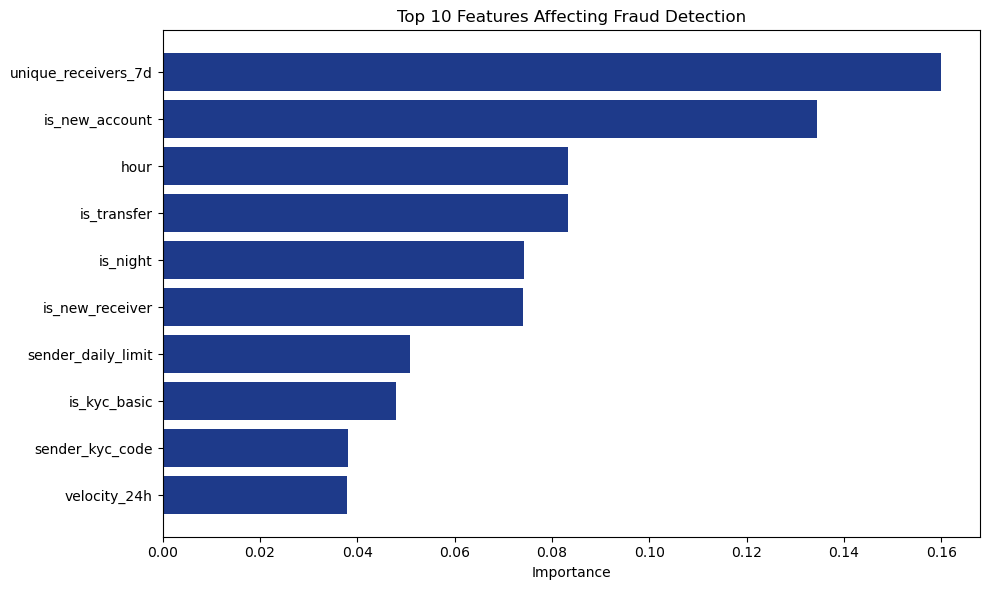

In [46]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

# Load the model
art = joblib.load('yemen_fraud_model_production.pkl')
model = art['model']
features = art['features']

# Extract feature importance
importances = model.feature_importances_
feature_imp = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Print the top 10 features
print("Top 10 features influencing the model's decision:")
print(feature_imp.head(10).to_string(index=False))

# Plot
plt.figure(figsize=(10, 6))
plt.barh(feature_imp['Feature'].head(10), feature_imp['Importance'].head(10), color='#1E3A8A')
plt.xlabel('Importance')
plt.title('Top 10 Features Affecting Fraud Detection')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()